In [1]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
sns.set_theme(palette="colorblind")

In [2]:
n_records = None

## Loading bottle database

In [3]:
bottle = pd.read_csv('../data/bottle.csv', delimiter=',',encoding='iso-8859-1',nrows=n_records)
bottle.dataframeName = 'bottle.csv'
nRow, nCol = bottle.shape
print(f'There are {nRow} rows and {nCol} columns')

/tmp/ipykernel_51723/1691685039.py:1: DtypeWarning: Columns (47,61) have mixed types. Specify dtype option on import or set low_memory=False.
  bottle = pd.read_csv('../data/bottle.csv', delimiter=',',encoding='iso-8859-1',nrows=n_records)


There are 895371 rows and 62 columns


### Loading in the field descriptions

In [4]:
bottle_fd = pd.read_csv('../data/Bottle Field Descriptions.csv', delimiter=',',encoding='iso-8859-1',nrows=n_records)

def whatis(field_name,fd):
    print(f"Field Name: {field_name}")
    row = fd[fd['Field Name'] == field_name]
    
    if row.empty:
        print("Not found.\n")
        return
    
    # Use .iloc[0] to extract the scalar values from the filtered Series
    description = row['Description'].iloc[0]
    unit = row['Units'].iloc[0]
    
    print(f"Description: {description}")
    print(f"Unit: {unit}")
    print("-" * 40)

# Loop through each field name
for field_name in bottle.columns:
    whatis(field_name,bottle_fd)

Field Name: Cst_Cnt
Description: Cast Count - All CalCOFI casts ever conducted, consecutively numbered
Unit: n.a.
----------------------------------------
Field Name: Btl_Cnt
Description: Bottle Count - All CalCOFI bottles ever sampled, consecutively numbered
Unit: n.a.
----------------------------------------
Field Name: Sta_ID
Description: Line and Station [Line] [Station]
Unit: n.a.
----------------------------------------
Field Name: Depth_ID
Description: Uses the Cast_ID prefix ([Century]-[Year][Month][ShipCode]-[CastType][Julian Day]-[CastTime]-[Line][Sta]) but adds three additional variables: [Depth][Bottle]-[Rec_Ind]
Unit: n.a.
----------------------------------------
Field Name: Depthm
Description: Bottle depth in meters
Unit: meters
----------------------------------------
Field Name: T_degC
Description: Water temperature in degrees Celsius
Unit: degrees Celsius
----------------------------------------
Field Name: Salnty
Description: Salinity (Practical Salinity Scale 1978)
U

In [5]:
bottle.head(5)

,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,...,R_DYNHT,R_Nuts,R_Oxy_µmol/Kg,DIC1,DIC2,TA1,TA2,pH1,pH2,DIC Quality Comment
0,1,1,054.0 056.0,19-4903CR-HY-060-0930-05400560-0000A-3,0,10.50,33.440,NaN,25.649,NaN,...,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,2,054.0 056.0,19-4903CR-HY-060-0930-05400560-0008A-3,8,10.46,33.440,NaN,25.656,NaN,...,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,3,054.0 056.0,19-4903CR-HY-060-0930-05400560-0010A-7,10,10.46,33.437,NaN,25.654,NaN,...,0.02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1,4,054.0 056.0,19-4903CR-HY-060-0930-05400560-0019A-3,19,10.45,33.420,NaN,25.643,NaN,...,0.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1,5,054.0 056.0,19-4903CR-HY-060-0930-05400560-0020A-7,20,10.45,33.421,NaN,25.643,NaN,...,0.04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
bottle.describe()

,Cst_Cnt,Btl_Cnt,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,BtlNum,...,R_Sal,R_DYNHT,R_Nuts,R_Oxy_µmol/Kg,DIC1,DIC2,TA1,TA2,pH1,pH2
count,895371.000000,895371.000000,895371.000000,884402.000000,848015.000000,725630.000000,842675.000000,690746.000000,690698.000000,138967.000000,...,842568.000000,848683.000000,90509.000000,690698.000000,1999.000000,224.000000,2084.000000,234.000000,84.000000,10.000000
mean,17747.708684,447686.027682,224.366744,10.819050,33.828139,3.399955,25.813919,57.225728,149.113798,10.432793,...,221.436542,0.428919,0.078659,149.114587,2153.239714,2168.148330,2256.055845,2278.858803,7.910983,7.948570
std,10574.444952,258471.536174,312.163785,4.230675,0.529472,2.084452,1.160761,37.321875,90.711832,6.196501,...,93.541289,0.379582,0.316057,90.712253,112.995202,154.852332,34.844435,58.496495,0.077666,0.021216
min,1.000000,1.000000,0.000000,1.440000,9.500900,-200.222000,16.996010,-3605.220000,-8740.570000,0.000000,...,0.400000,0.000000,0.000000,-8740.570000,1948.850000,1969.440000,2181.570000,2198.150000,7.618300,7.923100
25%,8551.000000,223843.500000,45.000000,7.710000,33.485000,1.370000,24.961000,21.300000,61.767330,5.000000,...,144.100000,0.130000,0.000000,61.767690,2028.330000,2008.977500,2230.322500,2229.062500,7.898675,7.931475
50%,17665.000000,447686.000000,125.000000,10.070000,33.857300,3.450000,25.989000,54.500000,151.493900,10.000000,...,203.900000,0.340000,0.000000,151.492450,2170.640000,2265.885000,2244.325000,2247.505000,7.928850,7.946650
75%,27426.000000,671528.500000,300.000000,13.900000,34.190000,5.500000,26.642000,97.700000,240.577200,16.000000,...,300.200000,0.630000,0.060000,240.576900,2253.810000,2315.525000,2278.505000,2316.452500,7.955100,7.963300
max,35644.000000,895398.000000,5351.000000,99.000000,37.034000,11.130000,250.784000,214.100000,485.701800,25.000000,...,5053.500000,3.880000,33.580000,485.701800,2367.800000,2364.420000,2434.900000,2437.000000,8.047700,7.988300


In [7]:
bottle[bottle['ChlorA'].notna()]

,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,...,R_DYNHT,R_Nuts,R_Oxy_µmol/Kg,DIC1,DIC2,TA1,TA2,pH1,pH2,DIC Quality Comment
472997,18832,472998,133.0 035.0,19-7303AX-HY-067-2005-13300350-0000B-3,0,19.230,34.49100,5.460,24.57500,103.90,...,0.00,NaN,237.9949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
472998,18832,472999,133.0 035.0,19-7303AX-HY-067-2005-13300350-0010A-3,10,19.220,34.49200,5.460,24.57800,103.90,...,0.03,NaN,237.9942,NaN,NaN,NaN,NaN,NaN,NaN,NaN
473027,18833,473028,142.7 008.0,19-7303AX-HY-069-1715-14270080-0000B-3,0,20.830,34.87700,5.200,24.44800,102.10,...,0.00,NaN,226.6899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
473028,18833,473029,142.7 008.0,19-7303AX-HY-069-1715-14270080-0010A-3,10,20.160,34.91100,4.740,24.65300,92.00,...,0.03,NaN,206.5952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
473030,18833,473031,142.7 008.0,19-7303AX-HY-069-1715-14270080-0030A-3,30,19.370,34.94300,4.120,24.88500,78.80,...,0.09,NaN,179.5316,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895359,35644,895387,093.3 100.0,20-21055S-MX-126-2005-09331000-0100A-3,100,11.320,25.64753,4.681,25.64753,75.59,...,NaN,0.0,203.8300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
895360,35644,895388,093.3 100.0,20-21055S-MX-126-2005-09331000-0125A-7,125,9.827,26.02236,3.513,26.02236,54.95,...,NaN,0.0,152.9100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
895361,35644,895389,093.3 100.0,20-21055S-MX-126-2005-09331000-0150A-7,150,9.403,26.19182,2.986,26.19182,46.30,...,NaN,0.0,129.9500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
895362,35644,895390,093.3 100.0,20-21055S-MX-126-2005-09331000-0151A-3,151,9.359,26.20768,2.973,26.20768,46.05,...,NaN,0.0,129.3800,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Loading Cast data

In [8]:
cast = pd.read_csv('../data/cast.csv', low_memory=False,encoding='iso-8859-1')

In [9]:
cast_fd = pd.read_csv('../data/Cast Field Descriptions.csv',encoding='iso-8859-1')

In [10]:
cast.columns

Index(['Cst_Cnt', 'Cruise_ID', 'Cruise', 'Cruz_Sta', 'DbSta_ID', 'Cast_ID',
       'Sta_ID', 'Quarter', 'Sta_Code', 'Distance', 'Date', 'Year', 'Month',
       'Julian_Date', 'Julian_Day', 'Time', 'Lat_Dec', 'Lat_Deg', 'Lat_Min',
       'Lat_Hem', 'Lon_Dec', 'Lon_Deg', 'Lon_Min', 'Lon_Hem', 'Rpt_Line',
       'St_Line', 'Ac_Line', 'Rpt_Sta', 'St_Station', 'Ac_Sta', 'Bottom_D',
       'Secchi', 'ForelU', 'Ship_Name', 'Ship_Code', 'Data_Type', 'Order_Occ',
       'Event_Num', 'Cruz_Leg', 'Orig_Sta_ID', 'Data_Or', 'Cruz_Num', 'IntChl',
       'IntC14', 'Inc_Str', 'Inc_End', 'PST_LAN', 'Civil_T', 'TimeZone',
       'Wave_Dir', 'Wave_Ht', 'Wave_Prd', 'Wind_Dir', 'Wind_Spd', 'Barometer',
       'Dry_T', 'Wet_T', 'Wea', 'Cloud_Typ', 'Cloud_Amt', 'Visibility'],
      dtype='object')

In [11]:
for field_name in cast.columns:
    whatis(field_name,cast_fd)

Field Name: Cst_Cnt
Description: Cast Count - All CalCOFI casts ever conducted, consecutively numbered
Unit: n.a.
----------------------------------------
Field Name: Cruise_ID
Description: Cruise identifier [Year]-[Month]-[Day]-C-[Ship Code]
Unit: n.a.
----------------------------------------
Field Name: Cruise
Description: Cruise Name [Year][Month]
Unit: n.a.
----------------------------------------
Field Name: Cruz_Sta
Description: Cruise Name and Station [Year][Month][Line][Station]
Unit: n.a.
----------------------------------------
Field Name: DbSta_ID
Description: Line and Station
Unit: n.a.
----------------------------------------
Field Name: Cast_ID
Description: Cast Identifier [Century] - [YY][MM][ShipCode] - [CastType][Julian Day] - [CastTime]-[Line][Sta]
Unit: n.a.
----------------------------------------
Field Name: Sta_ID
Description: Line and Station
Unit: n.a.
----------------------------------------
Field Name: Quarter
Description: Quarter of the year
Unit: n.a.
------

In [12]:
bottle.columns

Index(['Cst_Cnt', 'Btl_Cnt', 'Sta_ID', 'Depth_ID', 'Depthm', 'T_degC',
       'Salnty', 'O2ml_L', 'STheta', 'O2Sat', 'Oxy_µmol/Kg', 'BtlNum',
       'RecInd', 'T_prec', 'T_qual', 'S_prec', 'S_qual', 'P_qual', 'O_qual',
       'SThtaq', 'O2Satq', 'ChlorA', 'Chlqua', 'Phaeop', 'Phaqua', 'PO4uM',
       'PO4q', 'SiO3uM', 'SiO3qu', 'NO2uM', 'NO2q', 'NO3uM', 'NO3q', 'NH3uM',
       'NH3q', 'C14As1', 'C14A1p', 'C14A1q', 'C14As2', 'C14A2p', 'C14A2q',
       'DarkAs', 'DarkAp', 'DarkAq', 'MeanAs', 'MeanAp', 'MeanAq', 'IncTim',
       'LightP', 'R_Depth', 'R_TEMP', 'R_Sal', 'R_DYNHT', 'R_Nuts',
       'R_Oxy_µmol/Kg', 'DIC1', 'DIC2', 'TA1', 'TA2', 'pH1', 'pH2',
       'DIC Quality Comment'],
      dtype='object')

In [13]:
bottle[bottle['ChlorA'].notna()]

,Cst_Cnt,Btl_Cnt,Sta_ID,Depth_ID,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,...,R_DYNHT,R_Nuts,R_Oxy_µmol/Kg,DIC1,DIC2,TA1,TA2,pH1,pH2,DIC Quality Comment
472997,18832,472998,133.0 035.0,19-7303AX-HY-067-2005-13300350-0000B-3,0,19.230,34.49100,5.460,24.57500,103.90,...,0.00,NaN,237.9949,NaN,NaN,NaN,NaN,NaN,NaN,NaN
472998,18832,472999,133.0 035.0,19-7303AX-HY-067-2005-13300350-0010A-3,10,19.220,34.49200,5.460,24.57800,103.90,...,0.03,NaN,237.9942,NaN,NaN,NaN,NaN,NaN,NaN,NaN
473027,18833,473028,142.7 008.0,19-7303AX-HY-069-1715-14270080-0000B-3,0,20.830,34.87700,5.200,24.44800,102.10,...,0.00,NaN,226.6899,NaN,NaN,NaN,NaN,NaN,NaN,NaN
473028,18833,473029,142.7 008.0,19-7303AX-HY-069-1715-14270080-0010A-3,10,20.160,34.91100,4.740,24.65300,92.00,...,0.03,NaN,206.5952,NaN,NaN,NaN,NaN,NaN,NaN,NaN
473030,18833,473031,142.7 008.0,19-7303AX-HY-069-1715-14270080-0030A-3,30,19.370,34.94300,4.120,24.88500,78.80,...,0.09,NaN,179.5316,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
895359,35644,895387,093.3 100.0,20-21055S-MX-126-2005-09331000-0100A-3,100,11.320,25.64753,4.681,25.64753,75.59,...,NaN,0.0,203.8300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
895360,35644,895388,093.3 100.0,20-21055S-MX-126-2005-09331000-0125A-7,125,9.827,26.02236,3.513,26.02236,54.95,...,NaN,0.0,152.9100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
895361,35644,895389,093.3 100.0,20-21055S-MX-126-2005-09331000-0150A-7,150,9.403,26.19182,2.986,26.19182,46.30,...,NaN,0.0,129.9500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
895362,35644,895390,093.3 100.0,20-21055S-MX-126-2005-09331000-0151A-3,151,9.359,26.20768,2.973,26.20768,46.05,...,NaN,0.0,129.3800,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
bottle.dropna(subset=['ChlorA'],inplace=True)

In [15]:
bottle.shape

(245666, 62)

In [16]:
bottle_cast_merge = pd.merge(bottle,cast,on="Cst_Cnt")

<Axes: xlabel='Distance', ylabel='ChlorA'>

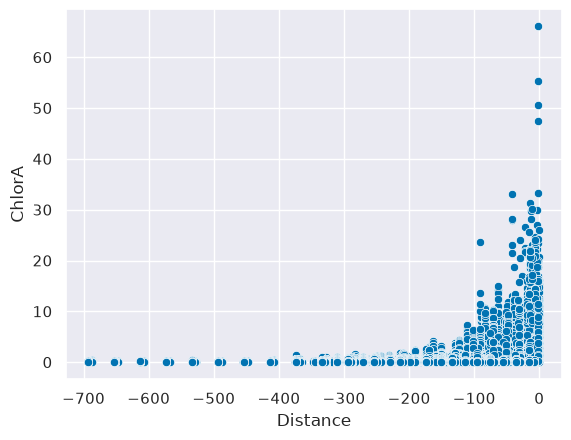

In [17]:
sns.scatterplot(bottle_cast_merge,y='ChlorA',x='Distance')

<Axes: xlabel='Month', ylabel='ChlorA'>

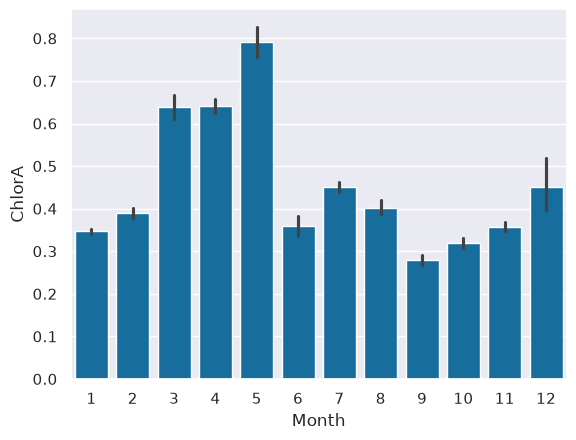

In [18]:
sns.barplot(bottle_cast_merge,y='ChlorA',x='Month')

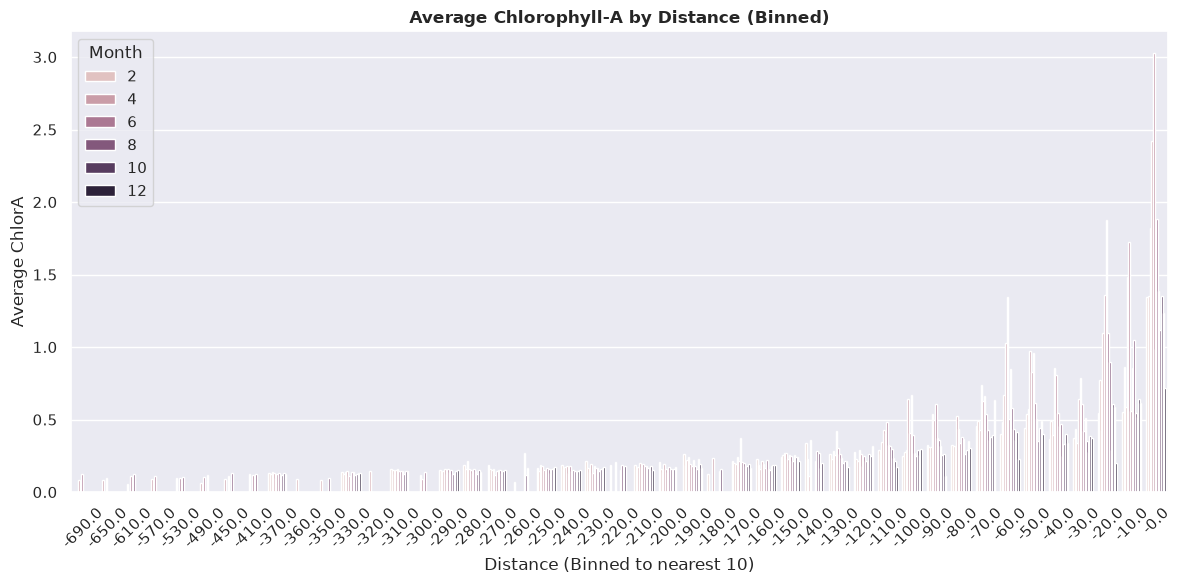

In [19]:

plt.figure(figsize=(12, 6))
bottle_cast_merge['Distance_Bin'] = bottle_cast_merge['Distance'].round(-1) # Rounds to nearest 10
sns.barplot(
    data=bottle_cast_merge, 
    x='Distance_Bin', 
    y='ChlorA',
    hue='Month',
    errorbar=None    # Turns off expensive confidence interval calculations
)
plt.title('Average Chlorophyll-A by Distance (Binned)', fontweight='bold')
plt.xlabel('Distance (Binned to nearest 10)')
plt.ylabel('Average ChlorA')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
for col in bottle_cast_merge.columns:
    print(col)

Cst_Cnt
Btl_Cnt
Sta_ID_x
Depth_ID
Depthm
T_degC
Salnty
O2ml_L
STheta
O2Sat
Oxy_µmol/Kg
BtlNum
RecInd
T_prec
T_qual
S_prec
S_qual
P_qual
O_qual
SThtaq
O2Satq
ChlorA
Chlqua
Phaeop
Phaqua
PO4uM
PO4q
SiO3uM
SiO3qu
NO2uM
NO2q
NO3uM
NO3q
NH3uM
NH3q
C14As1
C14A1p
C14A1q
C14As2
C14A2p
C14A2q
DarkAs
DarkAp
DarkAq
MeanAs
MeanAp
MeanAq
IncTim
LightP
R_Depth
R_TEMP
R_Sal
R_DYNHT
R_Nuts
R_Oxy_µmol/Kg
DIC1
DIC2
TA1
TA2
pH1
pH2
DIC Quality Comment
Cruise_ID
Cruise
Cruz_Sta
DbSta_ID
Cast_ID
Sta_ID_y
Quarter
Sta_Code
Distance
Date
Year
Month
Julian_Date
Julian_Day
Time
Lat_Dec
Lat_Deg
Lat_Min
Lat_Hem
Lon_Dec
Lon_Deg
Lon_Min
Lon_Hem
Rpt_Line
St_Line
Ac_Line
Rpt_Sta
St_Station
Ac_Sta
Bottom_D
Secchi
ForelU
Ship_Name
Ship_Code
Data_Type
Order_Occ
Event_Num
Cruz_Leg
Orig_Sta_ID
Data_Or
Cruz_Num
IntChl
IntC14
Inc_Str
Inc_End
PST_LAN
Civil_T
TimeZone
Wave_Dir
Wave_Ht
Wave_Prd
Wind_Dir
Wind_Spd
Barometer
Dry_T
Wet_T
Wea
Cloud_Typ
Cloud_Amt
Visibility
Distance_Bin


In [21]:
whatis('TA1',bottle_fd)

Field Name: TA1
Description: Total Alkalinity micromoles per kilogram solution
Unit: micromoles per kilogram
----------------------------------------


In [22]:
for col in bottle_cast_merge.columns:
    if bottle_cast_merge[col].isna().sum() == bottle_cast_merge.shape[0]:
        bottle_cast_merge.drop(col,axis=1,inplace=True)

In [23]:
for col in bottle_cast_merge.columns:
    print(col)

Cst_Cnt
Btl_Cnt
Sta_ID_x
Depth_ID
Depthm
T_degC
Salnty
O2ml_L
STheta
O2Sat
Oxy_µmol/Kg
BtlNum
RecInd
T_prec
T_qual
S_prec
S_qual
P_qual
O_qual
SThtaq
O2Satq
ChlorA
Chlqua
Phaeop
Phaqua
PO4uM
PO4q
SiO3uM
SiO3qu
NO2uM
NO2q
NO3uM
NO3q
NH3uM
NH3q
C14As1
C14A1p
C14A1q
C14As2
C14A2p
C14A2q
DarkAs
DarkAp
DarkAq
MeanAs
MeanAp
MeanAq
IncTim
LightP
R_Depth
R_TEMP
R_Sal
R_DYNHT
R_Nuts
R_Oxy_µmol/Kg
DIC1
DIC2
TA1
TA2
pH1
pH2
DIC Quality Comment
Cruise_ID
Cruise
Cruz_Sta
DbSta_ID
Cast_ID
Sta_ID_y
Quarter
Sta_Code
Distance
Date
Year
Month
Julian_Date
Julian_Day
Time
Lat_Dec
Lat_Deg
Lat_Min
Lat_Hem
Lon_Dec
Lon_Deg
Lon_Min
Lon_Hem
Rpt_Line
St_Line
Ac_Line
Rpt_Sta
St_Station
Ac_Sta
Bottom_D
Secchi
ForelU
Ship_Name
Ship_Code
Data_Type
Order_Occ
Event_Num
Cruz_Leg
Orig_Sta_ID
Data_Or
Cruz_Num
IntChl
IntC14
Inc_Str
Inc_End
PST_LAN
Civil_T
TimeZone
Wave_Dir
Wave_Ht
Wave_Prd
Wind_Dir
Wind_Spd
Barometer
Dry_T
Wet_T
Wea
Cloud_Typ
Cloud_Amt
Visibility
Distance_Bin


In [24]:
x = """Depthm
T_degC
Salnty
O2ml_L
STheta
O2Sat
Oxy_µmol/Kg
ChlorA
Phaeop
PO4uM
SiO3uM
NO2uM
NO3uM
NH3uM
C14As1
C14As2
DarkAs
MeanAs
LightP
R_DYNHT
R_Nuts
DIC1
DIC2
TA1
TA2
pH1
pH2
Quarter
Distance
Lat_Dec
Lat_Deg
Lat_Min
Lon_Dec
Lon_Deg
Lon_Min
Rpt_Line
St_Line
Ac_Line
Rpt_Sta
St_Station
Ac_Sta
Bottom_D
Secchi
ForelU
Order_Occ
Event_Num
Cruz_Leg
Data_Or
Cruz_Num
IntChl
IntC14
Inc_Str
Inc_End
PST_LAN
Civil_T
Wave_Dir
Wave_Ht
Wave_Prd
Wind_Dir
Wind_Spd
Barometer
Dry_T
Wet_T
Wea
Cloud_Typ
Cloud_Amt
Visibility
Distance_Bin"""
features = x.split("\n")

In [25]:
pd.set_option('display.max_columns', None)
bottle_cast_merge[features].head(1)

,Depthm,T_degC,Salnty,O2ml_L,STheta,O2Sat,Oxy_µmol/Kg,ChlorA,Phaeop,PO4uM,SiO3uM,NO2uM,NO3uM,NH3uM,C14As1,C14As2,DarkAs,MeanAs,LightP,R_DYNHT,R_Nuts,DIC1,DIC2,TA1,TA2,pH1,pH2,Quarter,Distance,Lat_Dec,Lat_Deg,Lat_Min,Lon_Dec,Lon_Deg,Lon_Min,Rpt_Line,St_Line,Ac_Line,Rpt_Sta,St_Station,Ac_Sta,Bottom_D,Secchi,ForelU,Order_Occ,Event_Num,Cruz_Leg,Data_Or,Cruz_Num,IntChl,IntC14,Inc_Str,Inc_End,PST_LAN,Civil_T,Wave_Dir,Wave_Ht,Wave_Prd,Wind_Dir,Wind_Spd,Barometer,Dry_T,Wet_T,Wea,Cloud_Typ,Cloud_Amt,Visibility,Distance_Bin
0,0,19.23,34.491,5.46,24.575,103.9,237.9949,0.64,0.47,NaN,NaN,NaN,1.3,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,25.85,25,51.0,-113.5,-113,30.0,132.8,133.0,132.8,34.8,35.0,34.8,817.0,NaN,NaN,NaN,2401.0,NaN,3101,7303,6.5,NaN,NaN,NaN,NaN,NaN,31.0,3.0,6.0,33.0,12.0,1001.6,19.0,15.0,1.0,6.0,7.0,NaN,NaN


<Axes: >

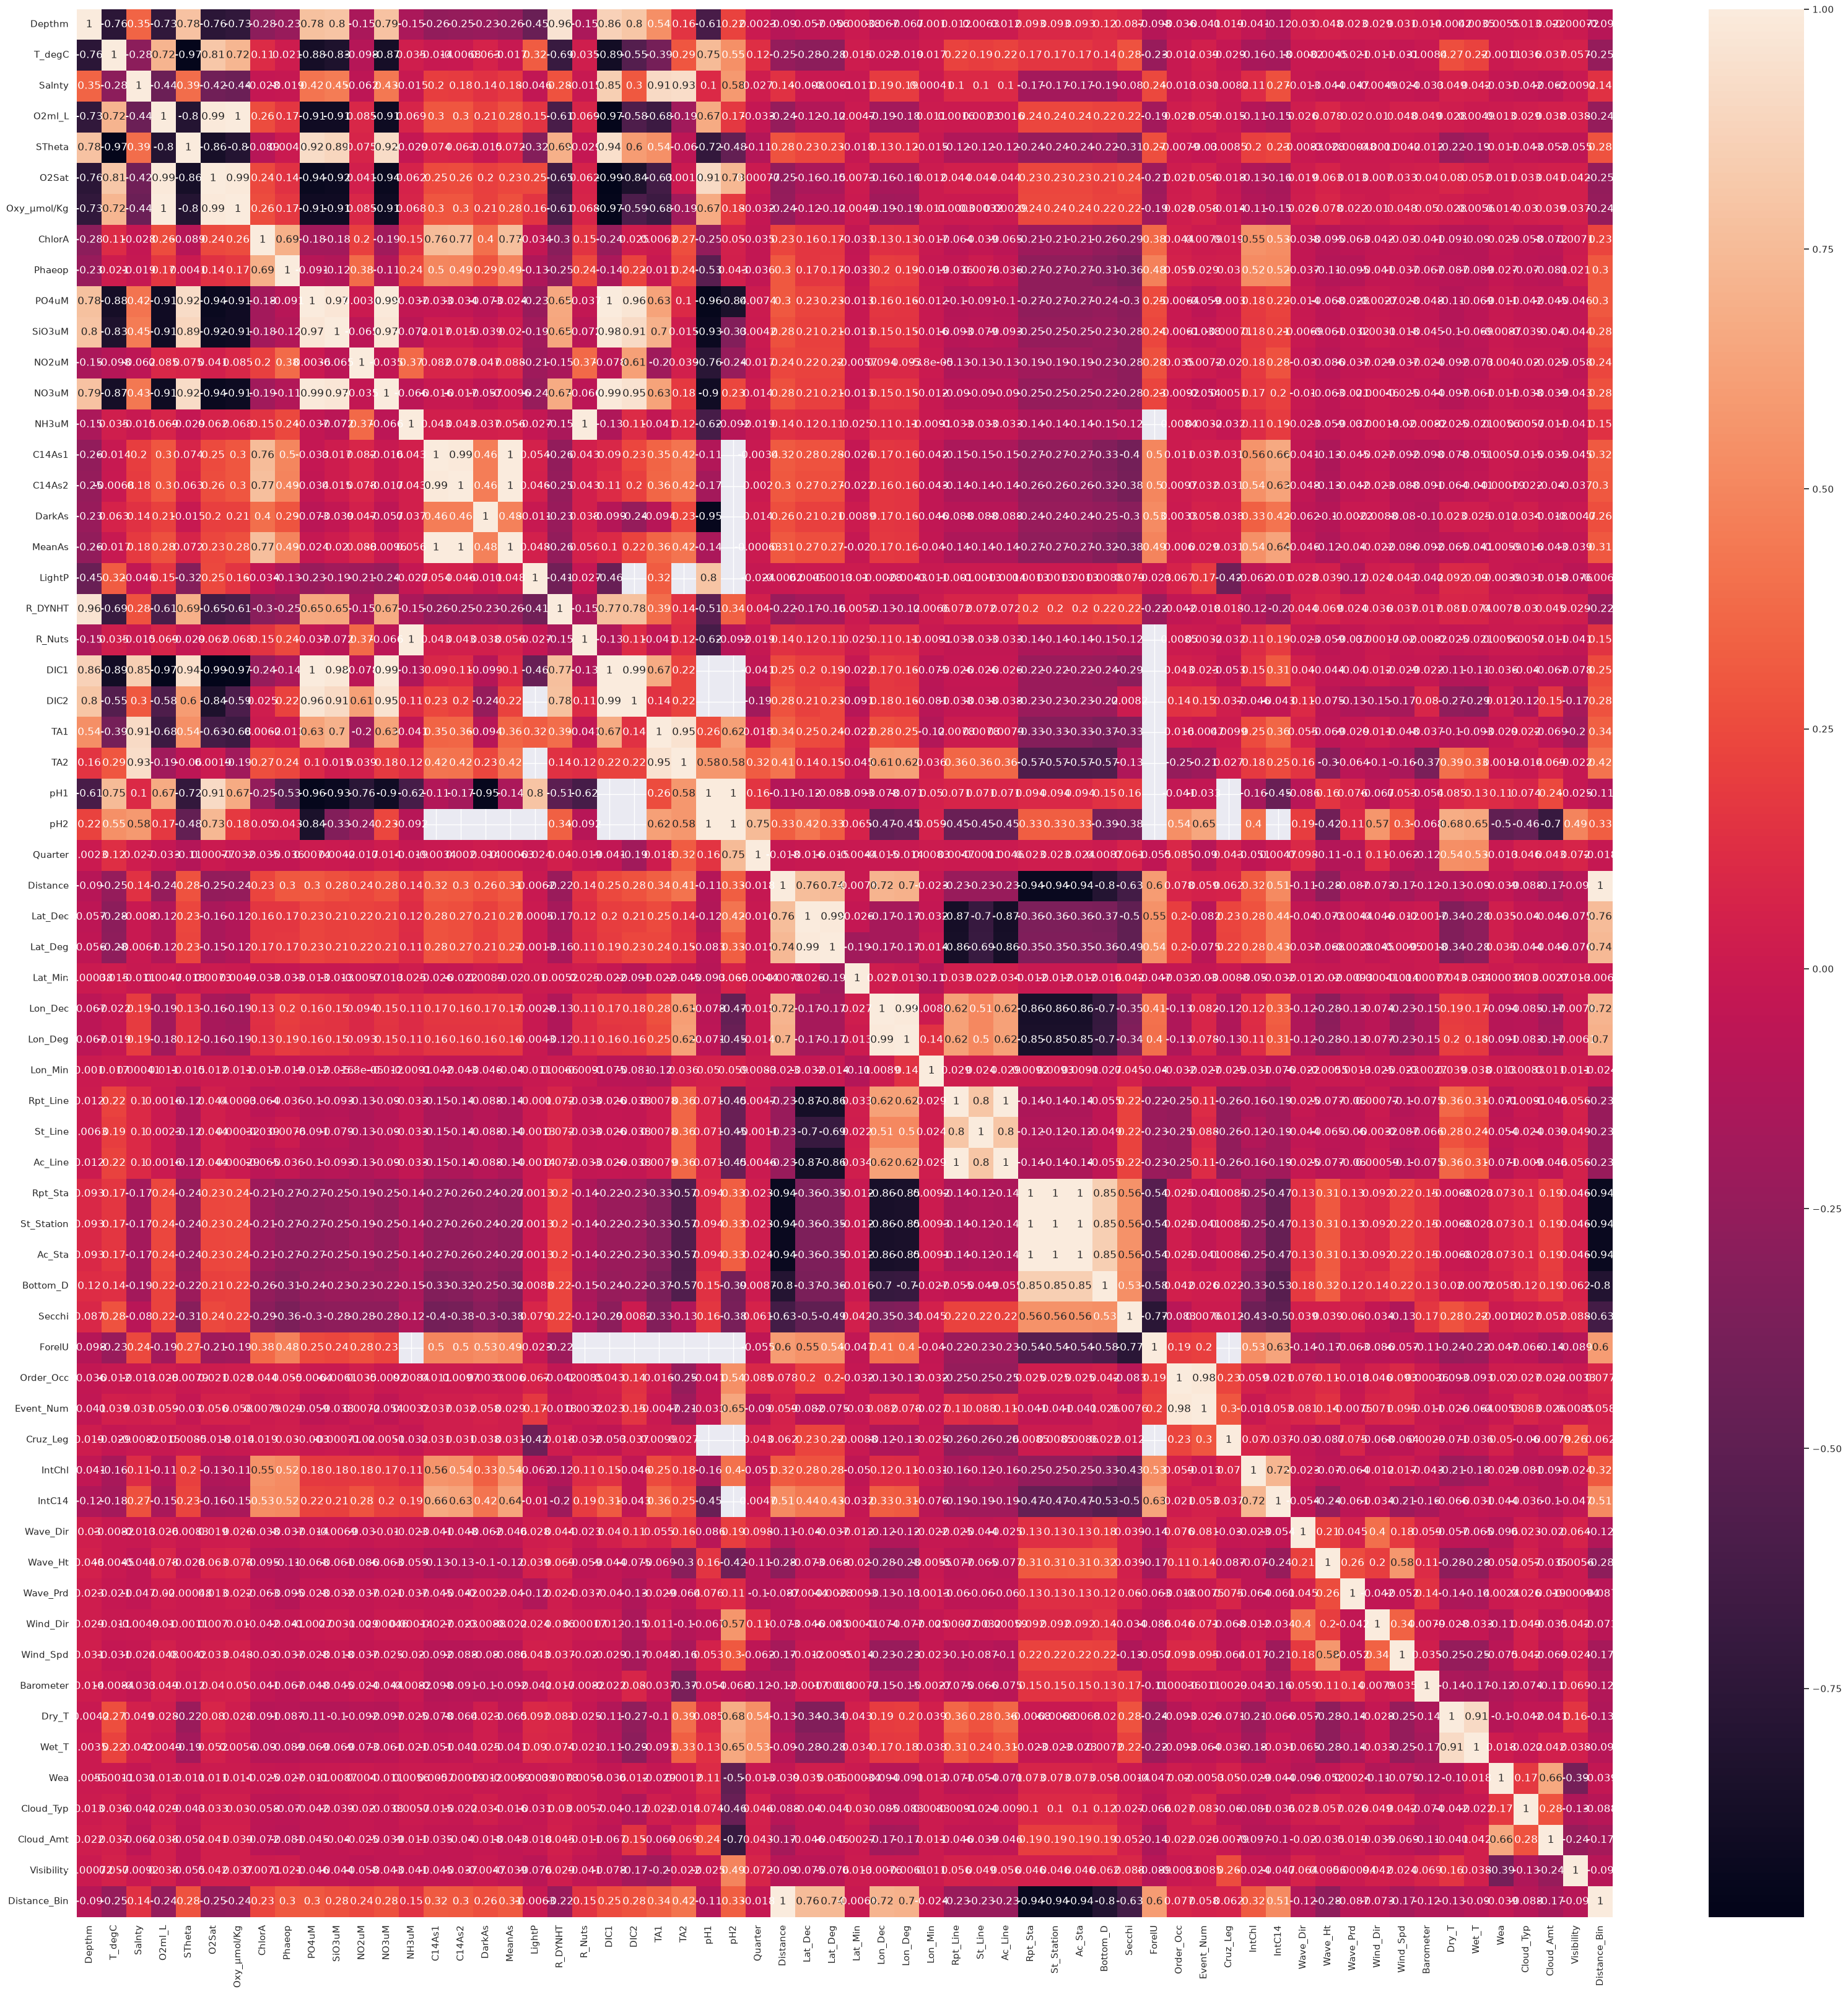

In [26]:
plt.figure(figsize=(40,40))
sns.heatmap(bottle_cast_merge[features].corr(numeric_only=True),annot=True)